# LEDGAR — fine-tuning DistilBERT (milestone m4)

> **Summary**
> - Every parameter of DistilBERT (67 M, with a new 100-way head) fine-tuned on the 60 000 training clauses at
>   512 tokens, on Colab A100s: 3.6 minutes for a 3-epoch run, 11.6 minutes for a 10-epoch run.
> - Learning rate chosen on validation: 5e-5 (macro-F1 0.791), the largest of the three tried. At 3 epochs every
>   run was still improving at its last epoch, and the three seeds agree to ±0.0002.
> - Trained for 10 epochs, the same configuration reaches **0.820 ± 0.001** on validation over three seeds
>   (+2.9 points), within 0.7 point of the TF-IDF baseline (0.827).
> - From epoch 4 the validation loss rises while macro-F1 keeps improving: the model grows over-confident, so its
>   probabilities must not be read as calibrated confidence.

The runs were trained on Colab GPUs with `scripts/train.py` (cards in `colab/run_m4.ipynb` and
`colab/run_m4_10epochs.ipynb`): three learning rates on validation, three seeds of the chosen one, then the
same configuration trained for 10 epochs instead of 3. This notebook checks the pieces on the real data and
analyses the saved runs. It trains nothing; the test scores are read in `06_evaluation.ipynb` only.

## Setup

In [1]:
import json
import math
import tempfile
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from huggingface_hub.utils import logging as hub_logging
from transformers import DataCollatorWithPadding

from ledgar import data, runs, train_bert
from ledgar.config import Config, set_seed

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
hub_logging.set_verbosity_error()
pd.set_option("display.width", 140)

cfg = Config.from_env()
set_seed(cfg.seed)
RESULTS, FIGURES = cfg.path("results"), cfg.path(cfg.reports_dir, "figures")
ledgar = data.load_ledgar(cfg)
LABELS = data.label_names(ledgar)
tokenizer = train_bert.load_tokenizer(cfg)
print(cfg)
print(
    f"effective batch {cfg.batch_size * cfg.grad_accum} ({cfg.batch_size} x {cfg.grad_accum} on this device; "
    f"32 x 1 on the A100 runs) | warmup {cfg.warmup_ratio} | weight decay {cfg.weight_decay}"
)

fast_run=False | seed=0 | device=mps | precision=fp32 | batch_size=8 | grad_accum=4 | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=3
effective batch 32 (8 x 4 on this device; 32 x 1 on the A100 runs) | warmup 0.1 | weight decay 0.01


## 1. What does DistilBERT actually read from a clause?

The model reads WordPiece sub-words from its own vocabulary of 30 522 pieces, lower-cased: a word it never
saw as a whole is cut into known pieces, so nothing is unknown. Each clause is wrapped in `[CLS]` … `[SEP]`
and cut at `max_length` = 512 tokens; padding is added later, batch by batch.

In [2]:
clause = "The Indemnifying Party shall indemnify the Indemnified Party against any Losses."
pieces = tokenizer.convert_ids_to_tokens(tokenizer(clause)["input_ids"])
train_tok = train_bert.tokenize_split(ledgar["train"], tokenizer, cfg.max_length)
lengths = np.array([len(ids) for ids in train_tok["input_ids"]])
longest = train_tok[int(lengths.argmax())]["input_ids"]
assert pieces[0] == "[CLS]" and pieces[-1] == "[SEP]" and longest[-1] == tokenizer.sep_token_id
assert lengths.max() <= cfg.max_length and len(set(lengths)) > 1, "truncated, not padded yet"
print(" ".join(pieces))
print(
    f"{100 * np.mean(lengths == cfg.max_length):.1f} % of training clauses are cut at {cfg.max_length} tokens"
)

[CLS] the ind ##em ##ni ##fying party shall ind ##em ##ni ##fy the ind ##em ##nified party against any losses . [SEP]
1.8 % of training clauses are cut at 512 tokens


→ **Consequence:** legal vocabulary is not in DistilBERT's general-English word list: *indemnifying* becomes four pieces,
which the model has to recombine. At 512 tokens, 1.8 % of the training clauses lose their end, against 13.5 % at
256 (`01_explore_ledgar`).

## 2. Is the model set up as intended before training?

The pretrained body is kept and a new classification head (768 → 768 → 100) is added, initialised at random:
before any update, the predicted distribution should be close to uniform, a loss of $\ln 100 = 4.61$. The
training arguments must select the epoch on validation macro-F1 and warm the learning rate up.

In [3]:
set_seed(cfg.seed)
model = train_bert.make_model(cfg, LABELS)
trainable, total = train_bert.count_parameters(model)
head = sum(p.numel() for n, p in model.named_parameters() if n.startswith(("pre_classifier", "classifier")))
first32 = train_tok.remove_columns("index").select(range(32))
loss0 = train_bert.initial_loss(model, DataCollatorWithPadding(tokenizer)([first32[i] for i in range(32)]))
args = train_bert.make_args(cfg, tempfile.mkdtemp(), cfg.lr_full)
steps = math.ceil(60_000 / (cfg.batch_size * cfg.grad_accum)) * cfg.epochs
assert head == 768 * 768 + 768 + 768 * 100 + 100 and total == 66_362_880 + head
assert abs(loss0 - math.log(100)) < 0.5
assert args.metric_for_best_model == "macro_f1" and args.load_best_model_at_end and args.warmup_steps == 0.1
assert args.train_sampling_strategy == "group_by_length" and args.max_grad_norm == 1.0
print(f"{total:,} parameters, all trainable; new head {head:,} | loss before training {loss0:.3f}")
print(f"{steps:,} optimisation steps over {cfg.epochs} epochs, {round(cfg.warmup_ratio * steps)} of warmup")
print(f"memory for weights, gradients and Adam: {train_bert.training_memory_gb(0, trainable):.2f} GB")

67,030,372 parameters, all trainable; new head 667,492 | loss before training 4.617
5,625 optimisation steps over 3 epochs, 562 of warmup
memory for weights, gradients and Adam: 1.07 GB


→ **Consequence:** the setup is as intended: 67 M trainable parameters of which 0.67 M in the new head, a loss of 4.62 at
step 0 (a uniform guess over 100 types gives 4.61), 5 625 optimisation steps for 3 epochs with the first 562 used
to warm the learning rate up, and about 1.1 GB for weights, gradients and Adam states.

## 3. Which learning rate? (validation, seed 0)

Three runs, identical except for the peak learning rate. The training loss is logged every 50 steps; a sudden
jump followed by a flat loss would be the sign of a rate too high for a pretrained model.

,lr,val_macro_f1,val_accuracy,best_epoch,steps,minutes,gpu
0,2e-5,0.7547,0.8497,3.0,5625,3.5700,NVIDIA A100-SXM4-40GB
1,3e-5,0.7743,0.8585,3.0,5625,3.6283,NVIDIA A100-SXM4-40GB
2,5e-5,0.7909,0.8652,3.0,5625,3.5750,NVIDIA A100-SXM4-40GB


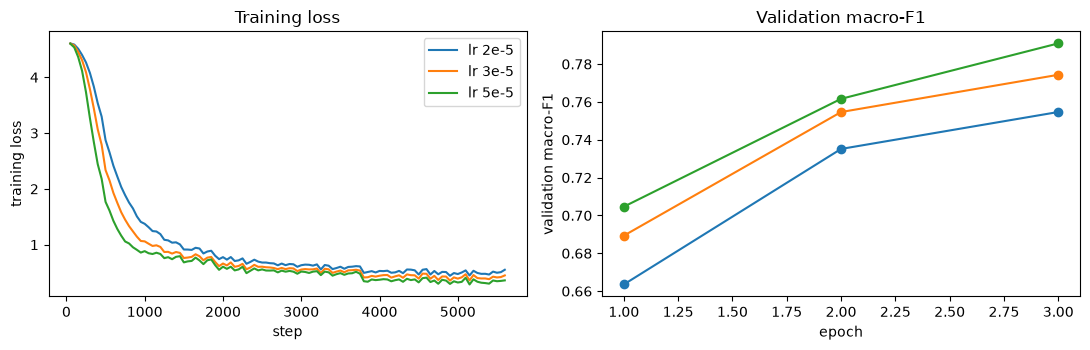

In [4]:
run_dirs = {}
for lr in ("2e-5", "3e-5", "5e-5"):
    name = f"bert_lr{lr}_seed0"
    run_dirs[lr] = RESULTS / name if (RESULTS / name).exists() else RESULTS / "search" / name
rows, curves = [], {}
for lr, run_dir in run_dirs.items():
    run = runs.load_run(run_dir)
    history = json.loads((run_dir / "log_history.json").read_text())
    curves[lr] = history
    evals = [h for h in history if "eval_macro_f1" in h]
    rows.append(
        {
            "lr": lr,
            "val_macro_f1": run["metrics"]["val"]["macro_f1"],
            "val_accuracy": run["metrics"]["val"]["accuracy"],
            "best_epoch": max(evals, key=lambda h: h["eval_macro_f1"])["epoch"],
            "steps": run["metrics"]["global_step"],
            "minutes": run["manifest"]["duration_s"] / 60,
            "gpu": run["manifest"]["gpu"],
        }
    )
lr_search = pd.DataFrame(rows)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for lr, history in curves.items():
    train = [h for h in history if "loss" in h]
    evals = [h for h in history if "eval_macro_f1" in h]
    ax1.plot([h["step"] for h in train], [h["loss"] for h in train], label=f"lr {lr}")
    ax2.plot([h["epoch"] for h in evals], [h["eval_macro_f1"] for h in evals], marker="o", label=f"lr {lr}")
ax1.set(xlabel="step", ylabel="training loss", title="Training loss")
ax2.set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1")
ax1.legend()
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "bert_lr_curves.png", dpi=150)
lr_search.round(4)

→ **Consequence:** the largest learning rate wins (0.755, 0.774, 0.791 for 2e-5, 3e-5, 5e-5), the training loss falls
smoothly (no jump of the kind a too-high rate causes), and every run peaks at its third and last epoch. Within 3
epochs the model is still learning: a higher rate simply covers more ground. 5e-5 is kept.

## 4. How stable is the result across seeds?

Seeds 0, 1 and 2 at the chosen learning rate. Their test predictions exist (written once per run) and are read
in `06_evaluation.ipynb`.

In [5]:
rows = []
for seed in (0, 1, 2):
    run = runs.load_run(RESULTS / f"bert_lr5e-5_seed{seed}")
    rows.append(
        {
            "seed": seed,
            "val_macro_f1": run["metrics"]["val"]["macro_f1"],
            "val_accuracy": run["metrics"]["val"]["accuracy"],
            "minutes": run["manifest"]["duration_s"] / 60,
        }
    )
seeds = pd.DataFrame(rows)
print(f"validation macro-F1 {seeds['val_macro_f1'].mean():.4f} ± {seeds['val_macro_f1'].std():.4f} (3 seeds)")
seeds.round(4)

validation macro-F1 0.7908 ± 0.0002 (3 seeds)


,seed,val_macro_f1,val_accuracy,minutes
0,0,0.7909,0.8652,3.5750
1,1,0.7909,0.8639,3.6217
2,2,0.7905,0.8636,3.6483


→ **Consequence:** the three seeds land within 0.0004 of each other (0.7908 ± 0.0002): a stable result, but 3.6 points below the
TF-IDF baseline on validation (0.8265). The validation analysis shows why: the model is level with TF-IDF on the
frequent types (mean F1 0.923 against 0.924) and far behind on the 22 rare ones (0.587 against 0.673), which
three passes over the data are not enough to learn.

## 5. Does training longer help? (3 epochs against 10, validation)

Every 3-epoch run was still improving at its last epoch, so the chosen configuration was trained again for 10
epochs, the best epoch still picked on validation macro-F1. The rule, fixed before these runs: keep 10 epochs
only if seed 0 beats its 3-epoch version on validation (`results/search/m4_choice_epochs.json`). This is a
follow-up experiment; the comparison registered in the README stays the 3-epoch one.

{"val_macro_f1": {"3 epochs": 0.7909229837679528, "10 epochs": 0.8202080947992958}, "keep_10_epochs": true}
10 epochs: validation macro-F1 0.8198 ± 0.0012 (3 seeds)


,seed,best_epoch,val_macro_f1,minutes
0,0,8.0,0.8202,11.5217
1,1,10.0,0.8207,11.7967
2,2,10.0,0.8185,11.5867


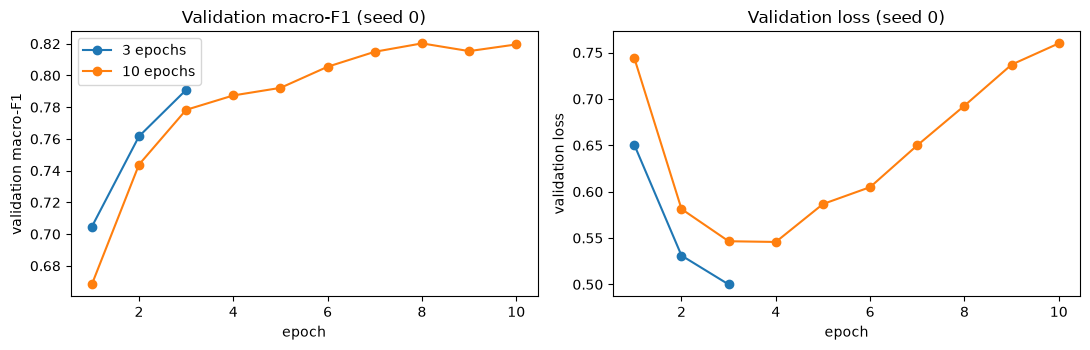

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for label, run in [("3 epochs", "bert_lr5e-5_seed0"), ("10 epochs", "bert_lr5e-5_ep10_seed0")]:
    evals = [h for h in json.loads((RESULTS / run / "log_history.json").read_text()) if "eval_macro_f1" in h]
    ax1.plot([h["epoch"] for h in evals], [h["eval_macro_f1"] for h in evals], marker="o", label=label)
    ax2.plot([h["epoch"] for h in evals], [h["eval_loss"] for h in evals], marker="o", label=label)
ax1.set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 (seed 0)")
ax2.set(xlabel="epoch", ylabel="validation loss", title="Validation loss (seed 0)")
ax1.legend()
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "bert_3_vs_10_epochs.png", dpi=150)
rows = []
for seed in (0, 1, 2):
    run = runs.load_run(RESULTS / f"bert_lr5e-5_ep10_seed{seed}")
    history = json.loads((RESULTS / f"bert_lr5e-5_ep10_seed{seed}" / "log_history.json").read_text())
    evals = [h for h in history if "eval_macro_f1" in h]
    rows.append(
        {
            "seed": seed,
            "best_epoch": max(evals, key=lambda h: h["eval_macro_f1"])["epoch"],
            "val_macro_f1": run["metrics"]["val"]["macro_f1"],
            "minutes": run["manifest"]["duration_s"] / 60,
        }
    )
ten = pd.DataFrame(rows)
print(json.dumps(json.loads((RESULTS / "search" / "m4_choice_epochs.json").read_text())["bert"]))
mean, std = ten["val_macro_f1"].mean(), ten["val_macro_f1"].std()
print(f"10 epochs: validation macro-F1 {mean:.4f} ± {std:.4f} (3 seeds)")
ten.round(4)

→ **Consequence:** 10 epochs add 2.9 points (0.8198 ± 0.0012), and the best epoch is the 8th or the 10th: the gain flattens
(+0.005 over the last three epochs), so more epochs would add little. Meanwhile the validation loss is lowest at
epochs 3-4 and then climbs (0.54 → 0.76): the model keeps getting its decisions right more often while becoming
more and more sure of itself, including when wrong. Choosing the epoch on the loss would have kept epoch 3-4; on
macro-F1, the decision metric, it keeps 8-10. The 10-epoch model is the final full fine-tuning model; its test
scores and its comparison with TF-IDF are in `06_evaluation.ipynb`.

## Files used

`results/bert_lr*_seed*` and `results/bert_lr*_ep10_seed*` (final runs), `results/search/bert_lr*_seed0`
(learning-rate search), `results/search/m4_choice*.json` (the two automatic choices),
`reports/figures/bert_lr_curves.png`, `reports/figures/bert_3_vs_10_epochs.png`. The fine-tuned weights
(260 MB each) are kept outside git.